In [2]:
import os, gzip, zipfile, io, re, requests
from pathlib import Path
from itertools import combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, mannwhitneyu, kruskal
from statsmodels.stats.multitest import multipletests
from google.colab import files
sns.set_theme(style="whitegrid", palette="deep")

In [3]:
uploaded = files.upload()

Saving GSE100933.ipynb to GSE100933.ipynb


In [4]:
uploaded = files.upload()

Saving GSE276323.ipynb to GSE276323.ipynb


In [5]:
uploaded = files.upload()

Saving OSD_417.ipynb to OSD_417.ipynb
Saving OSD_608.ipynb to OSD_608.ipynb
Saving OSD_804.ipynb to OSD_804.ipynb


In [7]:
def localizar_ou_enviar(termos_busca, extensao=".csv", descricao=""):
    """Procura o arquivo em /content (incluindo subpastas). Se não achar, pede upload."""
    for caminho in Path("/content").rglob(f"*{extensao}"):
        nome_upper = caminho.name.upper()
        if any(termo.upper() in nome_upper for termo in termos_busca) and "DICTIONARY" not in nome_upper:
            print(f"✅ Arquivo encontrado ({descricao}): {caminho}")
            return str(caminho)

    print(f"⚠️ Arquivo de {descricao} não encontrado no Colab. Por favor, selecione-o abaixo:")
    enviado = files.upload()
    nome_enviado = next(iter(enviado))
    print(f"✅ Upload concluído: {nome_enviado}")
    return nome_enviado

# 1. Localizar (ou pedir upload) dos arquivos estruturais:
arq_804 = localizar_ou_enviar(
    termos_busca=["LSDS-130", "Cahill", "804", "microCT"],
    extensao=".csv",
    descricao="OSD-804 (LSDS-130 Micro-CT)"
)

arq_608 = localizar_ou_enviar(
    termos_busca=["LSDS-41", "pQCT", "608", "KoTRANSFORMED"],
    extensao=".csv",
    descricao="OSD-608 (LSDS-41 pQCT)"
)

⚠️ Arquivo de OSD-804 (LSDS-130 Micro-CT) não encontrado no Colab. Por favor, selecione-o abaixo:


Saving OSD_804.ipynb to OSD_804 (1).ipynb
✅ Upload concluído: OSD_804 (1).ipynb
⚠️ Arquivo de OSD-608 (LSDS-41 pQCT) não encontrado no Colab. Por favor, selecione-o abaixo:


Saving OSD_608.ipynb to OSD_608 (1).ipynb
✅ Upload concluído: OSD_608 (1).ipynb


In [12]:
def baixar_da_nasa_osdr(osd_id, termo_arquivo, nome_saida):
    """Busca o link assinado na API oficial da NASA OSDR e baixa o arquivo direto para o Colab."""
    print(f"Buscando {nome_saida} na API da NASA ({osd_id})...")
    url_versoes = f"https://osdr.nasa.gov/geode-py/ws/repo/studies/{osd_id}/versions"
    r = requests.get(url_versoes, timeout=60)

    nome_exato = None
    if r.ok:
        dados = r.json()
        for v in dados.get("versions", []):
            for cat in ["added", "modified"]:
                for arq in v.get(cat, []):
                    fname = arq.get("file_name", "")
                    if termo_arquivo.lower() in fname.lower():
                        nome_exato = fname

    if nome_exato:
        url_dl = f"https://osdr.nasa.gov/geode-py/ws/studies/{osd_id}/download"
        resp = requests.get(url_dl, params={"source": "datamanager", "file": nome_exato, "redirect": "false"}, timeout=60)
        if resp.ok and resp.text.strip().startswith("http"):
            arquivo_bin = requests.get(resp.text.strip(), timeout=120)
            if arquivo_bin.ok:
                Path(nome_saida).write_bytes(arquivo_bin.content)
                print(f"Baixado com sucesso: {nome_saida} ({len(arquivo_bin.content)/1024:.1f} KB)")
                return nome_saida

    print(f"Não foi possível baixar {nome_saida} automaticamente. Selecione o arquivo CSV no seu PC:")
    enviado = files.upload()
    return next(iter(enviado))

# 1. Baixar CSV do OSD-804 (LSDS-130 Micro-CT) direto da NASA
arq_804 = baixar_da_nasa_osdr(
    osd_id="OSD-804",
    termo_arquivo="LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv",
    nome_saida="LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv"
)

# 2. Baixar CSV do OSD-608 (LSDS-41 pQCT) direto da NASA
arq_608 = baixar_da_nasa_osdr(
    osd_id="OSD-608",
    termo_arquivo="KoTRANSFORMED.csv",
    nome_saida="LSDS-41_pQCT_KoTRANSFORMED.csv"
)

# 3. Baixar GSE100930 (Microarray da ISS) direto do NCBI GEO
print("Baixando GSE100930_series_matrix.txt.gz do NCBI GEO...")
!wget -q -O GSE100930_series_matrix.txt.gz "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE100nnn/GSE100930/matrix/GSE100930_series_matrix.txt.gz"
arq_930 = "GSE100930_series_matrix.txt.gz"
print("GSE100930 baixado com sucesso!")

# 4. Baixar Anotação GPL6244 direto do NCBI GEO (ou usar local)
if not os.path.exists("GPL6244-17930.txt"):
    print("Baixando tabela de anotação GPL6244...")
    !wget -q -O GPL6244.annot.gz "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL6nnn/GPL6244/annot/GPL6244.annot.gz"
    print("Anotação GPL6244 baixada!")

Buscando LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv na API da NASA (OSD-804)...
Baixado com sucesso: LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv (12.7 KB)
Buscando LSDS-41_pQCT_KoTRANSFORMED.csv na API da NASA (OSD-608)...
Baixado com sucesso: LSDS-41_pQCT_KoTRANSFORMED.csv (10.1 KB)
Baixando GSE100930_series_matrix.txt.gz do NCBI GEO...
GSE100930 baixado com sucesso!
Baixando tabela de anotação GPL6244...
Anotação GPL6244 baixada!


In [14]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind, mannwhitneyu, kruskal
from statsmodels.stats.multitest import multipletests

def cohen_d(x, y):
    n1, n2 = len(x), len(y)
    if n1 < 2 or n2 < 2: return np.nan
    s = np.sqrt(((n1 - 1) * np.var(x, ddof=1) + (n2 - 1) * np.var(y, ddof=1)) / (n1 + n2 - 2))
    return (np.mean(x) - np.mean(y)) / (s + 1e-9)

# OSD-804 (LSDS-130): Micro-CT em Voo Espacial Real (RR-1: FLT vs GC)

df_804 = pd.read_csv("LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv")

df_804["grupo_codigo"] = df_804["Sample Name"].str.split("_").str[1]
df_804["regiao_ossea"] = df_804["Sample Name"].str.extract(
    r"_(CorticalFemur|DistalFemur|FemoralHead|FemoralNeck|Vertebrae)$"
)

colunas_medidas_804 = df_804.select_dtypes(include="number").columns.tolist()
resultados_804 = []

for regiao in df_804["regiao_ossea"].dropna().unique():
    sub_reg = df_804[df_804["regiao_ossea"] == regiao]
    for col in colunas_medidas_804:
        flt = sub_reg[sub_reg["grupo_codigo"] == "FLT"][col].dropna()
        gc  = sub_reg[sub_reg["grupo_codigo"] == "GC"][col].dropna()
        viv = sub_reg[sub_reg["grupo_codigo"] == "VIV"][col].dropna()
        bsl = sub_reg[sub_reg["grupo_codigo"] == "BSL"][col].dropna()

        if len(flt) >= 3 and len(gc) >= 3:
            grupos_validos = [g.values for g in [bsl, viv, flt, gc] if len(g) > 0]
            _, p_kw = kruskal(*grupos_validos)
            _, p_mwu = mannwhitneyu(flt, gc, alternative="two-sided")
            d_val = cohen_d(flt, gc)
            pct_change = ((flt.mean() - gc.mean()) / gc.mean()) * 100

            resultados_804.append({
                "Dataset": "OSD-804 (Micro-CT RR-1)",
                "Eixo_Biologico": "1. Formação e Remodelação Óssea",
                "Regiao_Contexto": regiao,
                "Variavel": col,
                "Comparacao": "FLT vs GC",
                "Media_Flight": flt.mean(),
                "Media_Control": gc.mean(),
                "Variacao_%": pct_change,
                "Effect_Size_d": d_val,
                "p_kruskal_4grupos": p_kw,
                "p_raw": p_mwu
            })

df_res_804 = pd.DataFrame(resultados_804)
df_res_804["p_adj_holm"] = multipletests(df_res_804["p_raw"], method="holm")[1]
df_res_804["p_adj_fdr"]  = multipletests(df_res_804["p_raw"], method="fdr_bh")[1]

print("RESULTADOS ESTRUTURAIS OSD-804 (ORDENADOS POR P-VALOR BRUTO)")
display(df_res_804.sort_values("p_raw").round(4))

# OSD-608 (LSDS-41): pQCT Descarga Parcial (PWB20 vs PWB100)

colunas_608 = [
    "animal_id", "PWB", "duracao",
    "trab_BMD_0", "trab_BMD_1", "trab_BMD_2", "trab_BMD_4",
    "trab_change_1", "trab_change_2", "trab_change_4",
    "cort_BMD_0", "cort_BMD_1", "cort_BMD_2", "cort_BMD_4",
    "cort_change_1", "cort_change_2", "cort_change_4"
]
df_608 = pd.read_csv("LSDS-41_pQCT_KoTRANSFORMED.csv", skiprows=2, header=None, names=colunas_608)
for c in colunas_608[3:]:
    df_608[c] = pd.to_numeric(df_608[c], errors="coerce")

resultados_608 = []
for dur, col in [("1wk", "trab_change_1"), ("2wk", "trab_change_2"), ("4wk", "trab_change_4")]:
    sub = df_608[df_608["duracao"] == dur]
    g20 = sub[sub["PWB"] == "PWB20"][col].dropna()
    g100 = sub[sub["PWB"] == "PWB100"][col].dropna()
    _, p_mwu = mannwhitneyu(g20, g100, alternative="two-sided")
    resultados_608.append({
        "Dataset": "OSD-608 (pQCT PWB)",
        "Eixo_Biologico": "1. Formação e Remodelação Óssea",
        "Regiao_Contexto": f"Trabecular ({dur})",
        "Variavel": f"trab_BMD_change_{dur}",
        "Comparacao": "PWB20 vs PWB100",
        "Media_Flight": g20.mean(),
        "Media_Control": g100.mean(),
        "Variacao_%": g20.mean() - g100.mean(),
        "Effect_Size_d": cohen_d(g20, g100),
        "p_raw": p_mwu
    })
df_res_608 = pd.DataFrame(resultados_608)
df_res_608["p_adj_holm"] = multipletests(df_res_608["p_raw"], method="holm")[1]
df_res_608["p_adj_fdr"]  = multipletests(df_res_608["p_raw"], method="fdr_bh")[1]

print("RESULTADOS ESTRUTURAIS OSD-608 (PWB20 vs PWB100)")
display(df_res_608.round(4))

RESULTADOS ESTRUTURAIS OSD-804 (ORDENADOS POR P-VALOR BRUTO)


,Dataset,Eixo_Biologico,Regiao_Contexto,Variavel,Comparacao,Media_Flight,Media_Control,Variacao_%,Effect_Size_d,p_kruskal_4grupos,p_raw,p_adj_holm,p_adj_fdr
15,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,FemoralHead,bone_volume_total_volume_millimeter_cubed,FLT vs GC,39.8162,54.8780,-27.4459,-2.5367,0.0007,0.0016,0.0451,0.0451
19,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,FemoralHead,trabecular_bone_pattern_factor,FLT vs GC,9.5162,1.1120,755.7779,2.1741,0.0150,0.0062,0.1740,0.0462
9,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,DistalFemur,connectivity_density_per_millimeter_cubed,FLT vs GC,89.1789,186.3344,-52.1404,-1.4260,0.0006,0.0070,0.1888,0.0462
20,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,FemoralHead,trabecular_separation_millimeter,FLT vs GC,0.1200,0.0960,25.0000,2.3785,0.0074,0.0070,0.1888,0.0462
13,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,DistalFemur,trabecular_separation_millimeter,FLT vs GC,0.3151,0.2759,14.2029,1.2301,0.0005,0.0080,0.1991,0.0462
12,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,DistalFemur,trabecular_bone_pattern_factor,FLT vs GC,43.6219,34.2280,27.4452,1.6971,0.0106,0.0117,0.2797,0.0563
21,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,FemoralHead,trabecular_thickness_millimeter,FLT vs GC,0.0750,0.0880,-14.7727,-1.9680,0.0048,0.0152,0.3496,0.0630
8,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,DistalFemur,bone_volume_total_volume_millimeter_cubed,FLT vs GC,3.0899,6.7988,-54.5529,-1.2043,0.0018,0.0211,0.4649,0.0766
18,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,FemoralHead,trabecular_number_per_millimeter,FLT vs GC,5.3825,6.1500,-12.4797,-1.5214,0.0121,0.0295,0.6200,0.0951
14,OSD-804 (Micro-CT RR-1),1. Formação e Remodelação Óssea,DistalFemur,trabecular_thickness_millimeter,FLT vs GC,0.0433,0.0448,-3.2502,-0.2631,0.0252,0.0376,0.7527,0.1091


RESULTADOS ESTRUTURAIS OSD-608 (PWB20 vs PWB100)


,Dataset,Eixo_Biologico,Regiao_Contexto,Variavel,Comparacao,Media_Flight,Media_Control,Variacao_%,Effect_Size_d,p_raw,p_adj_holm,p_adj_fdr
0,OSD-608 (pQCT PWB),1. Formação e Remodelação Óssea,Trabecular (1wk),trab_BMD_change_1wk,PWB20 vs PWB100,-18.1333,-0.0714,-18.0619,-2.2773,0.0012,0.0023,0.0017
1,OSD-608 (pQCT PWB),1. Formação e Remodelação Óssea,Trabecular (2wk),trab_BMD_change_2wk,PWB20 vs PWB100,-27.1917,-8.8300,-18.3617,-1.9814,0.0017,0.0023,0.0017
2,OSD-608 (pQCT PWB),1. Formação e Remodelação Óssea,Trabecular (4wk),trab_BMD_change_4wk,PWB20 vs PWB100,-30.0600,-4.8308,-25.2292,-2.2815,0.0001,0.0004,0.0004


In [15]:

# GSE100930: Expressão Gênica em hBMSCs na ISS nos 4 Eixos Biológicos

dados_microarray = pd.read_csv("GSE100930_series_matrix.txt.gz", sep="\t", comment="!", index_col=0)

# Ler anotação (compatível com GPL6244.annot.gz baixado do NCBI ou GPL6244-17930.txt)
if os.path.exists("GPL6244-17930.txt"):
    anotacao_gpl = pd.read_csv("GPL6244-17930.txt", sep="\t", comment="#", dtype=str)
    def extrair_gene(valor):
        if pd.isna(valor) or valor == "---": return None
        partes = str(valor).split(" /// ")[0].split(" // ")
        return partes[1].strip() if len(partes) >= 2 else None
    anotacao = anotacao_gpl[["ID", "gene_assignment"]].copy()
    anotacao["gene"] = anotacao["gene_assignment"].apply(extrair_gene)
else:
    with gzip.open("GPL6244.annot.gz", "rt", encoding="utf-8", errors="ignore") as f:
        linhas_gpl = f.readlines()
    idx_ini = next(i for i, l in enumerate(linhas_gpl) if "!platform_table_begin" in l) + 1
    idx_fim = next(i for i, l in enumerate(linhas_gpl) if "!platform_table_end" in l)
    from io import StringIO
    anotacao_gpl = pd.read_csv(StringIO("".join(linhas_gpl[idx_ini:idx_fim])), sep="\t", dtype=str)
    anotacao = anotacao_gpl[["ID", "Gene symbol"]].copy()
    anotacao["gene"] = anotacao["Gene symbol"].str.split("///").str[0].str.strip()

anotacao["ID"] = anotacao["ID"].astype(str)

expressao = dados_microarray.copy()
expressao.index = expressao.index.astype(str)
expressao = expressao.reset_index().rename(columns={"ID_REF": "ID"})
expressao_anotada = expressao.merge(anotacao[["ID", "gene"]], on="ID", how="left")

flight_ost = ['GSM2696758', 'GSM2696759', 'GSM2696760']
flight_std = ['GSM2696761', 'GSM2696762', 'GSM2696763', 'GSM2696764']
ground_ost = ['GSM2696765', 'GSM2696766', 'GSM2696767']
ground_std = ['GSM2696768', 'GSM2696769', 'GSM2696770']

GENES_POR_EIXO = {
    "1. Formação e Remodelação Óssea": [
        "RUNX2", "ALPL", "BGLAP", "COL1A1", "SP7", "BMP2", "SPP1",
        "TNFRSF11B", "TNFSF11", "SOST", "CTNNB1", "LRP5", "MMP9"
    ],
    "2. Metabolismo Energético": [
        "LDHA", "LDHB", "HK2", "PKM", "HIF1A", "PPARGC1A", "SLC2A1", "PDK1", "TFAM"
    ],
    "3. Estresse Oxidativo": [
        "GCLC", "GCLM", "GSS", "GPX1", "GPX4", "GSR", "SOD1", "SOD2", "CAT", "NFE2L2", "HMOX1"
    ],
    "4. Metabolismo de Aminoácidos": [
        "BCAT1", "BCAT2", "BCKDHA", "BCKDHB", "SLC7A5", "MTOR", "ATF4", "EIF4EBP1"
    ]
}

mapa_gene_eixo = {g: eixo for eixo, lista in GENES_POR_EIXO.items() for g in lista}
df_genes_alvo = expressao_anotada[expressao_anotada["gene"].isin(mapa_gene_eixo.keys())].copy()
colunas_amostras = flight_ost + flight_std + ground_ost + ground_std
df_genes_agg = df_genes_alvo.groupby("gene")[colunas_amostras].mean()

resultados_930 = []
for meio, cols_f, cols_g in [
    ("Meio Osteogênico", flight_ost, ground_ost),
    ("Meio Standard", flight_std, ground_std),
    ("Global (Flight vs Ground)", flight_ost + flight_std, ground_ost + ground_std)
]:
    for gene, row in df_genes_agg.iterrows():
        vf = row[cols_f].values.astype(float)
        vg = row[cols_g].values.astype(float)
        log2fc = np.mean(vf) - np.mean(vg)
        d_val  = cohen_d(vf, vg)
        _, p_t = ttest_ind(vf, vg, equal_var=False)

        resultados_930.append({
            "Dataset": "GSE100930 (hBMSCs ISS)",
            "Eixo_Biologico": mapa_gene_eixo[gene],
            "Regiao_Contexto": meio,
            "Variavel": gene,
            "Comparacao": "Flight vs Ground",
            "Media_Flight": np.mean(vf),
            "Media_Control": np.mean(vg),
            "Log2FC": log2fc,
            "Effect_Size_d": d_val,
            "p_raw": p_t
        })

df_res_930 = pd.DataFrame(resultados_930)
df_res_930["p_adj_fdr"] = df_res_930.groupby("Regiao_Contexto")["p_raw"].transform(
    lambda x: multipletests(x, method="fdr_bh")[1]
)
df_res_930["p_adj_holm"] = df_res_930.groupby("Regiao_Contexto")["p_raw"].transform(
    lambda x: multipletests(x, method="holm")[1]
)

print("=== 2. TOP GENES DIFERENCIALMENTE EXPRESSOS NOS 4 EIXOS (GSE100930) ===")
display(df_res_930.sort_values("p_raw").head(20).round(4))

# 3. OSD-417: Vias Metabólicas (Ácido Lático, Glutationa, Leucina/Isoleucina) e Microbioma

def baixar_arquivo_osd417(nome_arquivo):
    url_api = "https://osdr.nasa.gov/geode-py/ws/studies/OSD-417/download"
    r = requests.get(url_api, params={"source": "datamanager", "file": nome_arquivo, "redirect": "false"}, timeout=60)
    if r.ok and r.text.strip().startswith("http"):
        down = requests.get(r.text.strip(), timeout=120)
        if down.ok:
            caminho = Path(f"/content/{nome_arquivo}")
            caminho.write_bytes(down.content)
            return caminho
    return None

resultados_417 = []

caminho_pw = baixar_arquivo_osd417("GLDS-417_GMetagenomics_Pathway-abundances-cpm_GLmetagenomics.tsv")
if caminho_pw and caminho_pw.exists():
    df_pw = pd.read_csv(caminho_pw, sep="\t")
    col_id = df_pw.columns[0]
    cols_f_417  = [c for c in df_pw.columns if c.startswith("F")]
    cols_gc_417 = [c for c in df_pw.columns if c.startswith("GC")]

    termos_eixos_417 = {
        "2. Metabolismo Energético": ["lactate", "lactic", "glycolysis", "pyruvate", "fermentation"],
        "3. Estresse Oxidativo": ["glutathione", "superoxide", "oxidative", "thioredoxin"],
        "4. Metabolismo de Aminoácidos": ["leucine", "isoleucine", "valine", "branched-chain"]
    }

    for eixo, termos in termos_eixos_417.items():
        padrao = "|".join(termos)
        mascara = df_pw[col_id].str.contains(padrao, case=False, na=False) & (~df_pw[col_id].str.contains(r"\|"))
        for _, row in df_pw[mascara].iterrows():
            vf = row[cols_f_417].values.astype(float)
            vg = row[cols_gc_417].values.astype(float)
            if np.mean(vf) + np.mean(vg) == 0: continue
            _, p_mwu = mannwhitneyu(vf, vg, alternative="two-sided")
            log2fc = np.log2((np.mean(vf) + 1e-3) / (np.mean(vg) + 1e-3))
            resultados_417.append({
                "Dataset": "OSD-417 (Vias Metabólicas RR-5)",
                "Eixo_Biologico": eixo,
                "Regiao_Contexto": "Metagenômica Funcional (CPM)",
                "Variavel": row[col_id][:50],
                "Comparacao": "Flight vs Ground",
                "Media_Flight": np.mean(vf),
                "Media_Control": np.mean(vg),
                "Log2FC": log2fc,
                "Effect_Size_d": cohen_d(vf, vg),
                "p_raw": p_mwu
            })

caminho_tax = baixar_arquivo_osd417("GLDS-417_GMetagenomics_Metaphlan-taxonomy_GLmetagenomics.tsv")
if caminho_tax and caminho_tax.exists():
    df_tax = pd.read_csv(caminho_tax, sep="\t")
    col_id_t = df_tax.columns[0]
    cols_f_t  = [c for c in df_tax.columns if c.startswith("F")]
    cols_gc_t = [c for c in df_tax.columns if c.startswith("GC")]

    sub_tax = df_tax[df_tax[col_id_t].str.contains("s__Lactobacillus_murinus|g__Dorea", case=False, na=False)]
    for _, row in sub_tax.iterrows():
        vf = row[cols_f_t].values.astype(float)
        vg = row[cols_gc_t].values.astype(float)
        if np.mean(vf) + np.mean(vg) > 0:
            _, p_mwu = mannwhitneyu(vf, vg, alternative="two-sided")
            log2fc = np.log2((np.mean(vf) + 1e-3) / (np.mean(vg) + 1e-3))
            resultados_417.append({
                "Dataset": "OSD-417 (Microbioma RR-5)",
                "Eixo_Biologico": "2. Metabolismo Energético",
                "Regiao_Contexto": "Taxonomia Intestinal",
                "Variavel": row[col_id_t].split("|")[-1],
                "Comparacao": "Flight vs Ground",
                "Media_Flight": np.mean(vf),
                "Media_Control": np.mean(vg),
                "Log2FC": log2fc,
                "Effect_Size_d": cohen_d(vf, vg),
                "p_raw": p_mwu
            })

df_res_417 = pd.DataFrame(resultados_417)
if not df_res_417.empty:
    df_res_417["p_adj_fdr"]  = multipletests(df_res_417["p_raw"], method="fdr_bh")[1]
    df_res_417["p_adj_holm"] = multipletests(df_res_417["p_raw"], method="holm")[1]
    print("RESULTADOS METABÓLICOS E MICROBIANOS (OSD-417)")
    display(df_res_417.sort_values("p_raw").head(15).round(4))

=== 2. TOP GENES DIFERENCIALMENTE EXPRESSOS NOS 4 EIXOS (GSE100930) ===


,Dataset,Eixo_Biologico,Regiao_Contexto,Variavel,Comparacao,Media_Flight,Media_Control,Log2FC,Effect_Size_d,p_raw,p_adj_fdr,p_adj_holm
50,GSE100930 (hBMSCs ISS),4. Metabolismo de Aminoácidos,Meio Standard,EIF4EBP1,Flight vs Ground,7.3084,5.9696,1.3388,12.2621,0.0000,0.0006,0.0006
27,GSE100930 (hBMSCs ISS),2. Metabolismo Energético,Meio Osteogênico,PKM,Flight vs Ground,10.9920,9.3976,1.5944,17.6496,0.0000,0.0011,0.0011
7,GSE100930 (hBMSCs ISS),3. Estresse Oxidativo,Meio Osteogênico,CAT,Flight vs Ground,8.1488,6.5123,1.6365,14.6008,0.0001,0.0015,0.0029
74,GSE100930 (hBMSCs ISS),1. Formação e Remodelação Óssea,Meio Standard,SOST,Flight vs Ground,5.5405,4.5100,1.0305,10.3361,0.0002,0.0037,0.0071
31,GSE100930 (hBMSCs ISS),4. Metabolismo de Aminoácidos,Meio Osteogênico,SLC7A5,Flight vs Ground,5.5007,8.1371,-2.6364,-18.1826,0.0003,0.0037,0.0105
109,GSE100930 (hBMSCs ISS),1. Formação e Remodelação Óssea,Global (Flight vs Ground),RUNX2,Flight vs Ground,8.0019,6.2208,1.7811,4.1931,0.0004,0.0109,0.0165
92,GSE100930 (hBMSCs ISS),3. Estresse Oxidativo,Global (Flight vs Ground),GCLM,Flight vs Ground,4.9343,5.9444,-1.0101,-2.7178,0.0005,0.0109,0.0212
3,GSE100930 (hBMSCs ISS),4. Metabolismo de Aminoácidos,Meio Osteogênico,BCAT2,Flight vs Ground,6.0241,4.6212,1.4028,8.3670,0.0007,0.0061,0.0266
11,GSE100930 (hBMSCs ISS),3. Estresse Oxidativo,Meio Osteogênico,GCLC,Flight vs Ground,7.2848,10.0177,-2.7329,-17.2403,0.0008,0.0061,0.0276
75,GSE100930 (hBMSCs ISS),1. Formação e Remodelação Óssea,Meio Standard,SP7,Flight vs Ground,5.6243,4.6967,0.9276,9.0303,0.0018,0.0151,0.0694


RESULTADOS METABÓLICOS E MICROBIANOS (OSD-417)


,Dataset,Eixo_Biologico,Regiao_Contexto,Variavel,Comparacao,Media_Flight,Media_Control,Log2FC,Effect_Size_d,p_raw,p_adj_fdr,p_adj_holm
10,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),"P461-PWY: hexitol fermentation to lactate, for...",Flight vs Ground,58.7421,30.8114,0.9309,1.8168,0.0028,0.0683,0.0905
30,OSD-417 (Vias Metabólicas RR-5),4. Metabolismo de Aminoácidos,Metagenômica Funcional (CPM),PWY-5104: L-isoleucine biosynthesis IV,Flight vs Ground,1.3849,17.0969,-3.6249,-1.4180,0.0048,0.0683,0.1493
4,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),GLYCOLYSIS-E-D: superpathway of glycolysis and...,Flight vs Ground,9.6707,34.5524,-1.8370,-1.2509,0.0091,0.0683,0.2733
6,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),P108-PWY: pyruvate fermentation to propanoate I,Flight vs Ground,15.1653,23.4950,-0.6315,-1.3307,0.0140,0.0683,0.4066
23,OSD-417 (Vias Metabólicas RR-5),3. Estresse Oxidativo,Metagenômica Funcional (CPM),NONOXIPENT-PWY: pentose phosphate pathway (non...,Flight vs Ground,256.2757,304.1333,-0.2470,-1.2882,0.0140,0.0683,0.4066
20,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),PWY-7111: pyruvate fermentation to isobutanol ...,Flight vs Ground,264.8128,313.5638,-0.2438,-1.3414,0.0140,0.0683,0.4066
21,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),PWY-8086: (S)-lactate fermentation to propanoa...,Flight vs Ground,0.0000,1.1561,-10.1763,-1.2121,0.0149,0.0683,0.4066
7,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),P122-PWY: heterolactic fermentation,Flight vs Ground,0.2530,2.3133,-3.1875,-1.2934,0.0296,0.1183,0.7395
16,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),PWY-5676: acetyl-CoA fermentation to butanoate II,Flight vs Ground,20.1814,33.9884,-0.7520,-0.9838,0.0890,0.3163,1.0000
22,OSD-417 (Vias Metabólicas RR-5),2. Metabolismo Energético,Metagenômica Funcional (CPM),PWY4LZ-257: superpathway of fermentation (Chla...,Flight vs Ground,46.2923,57.4943,-0.3126,-0.8954,0.1041,0.3233,1.0000


/tmp/ipykernel_1754/1818550724.py:75: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nsmallest(5, "p_raw"))
/tmp/ipykernel_1754/1818550724.py:75: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nsmallest(5, "p_raw"))
/tmp/ipykernel_1754/1818550724.py:75: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a futur

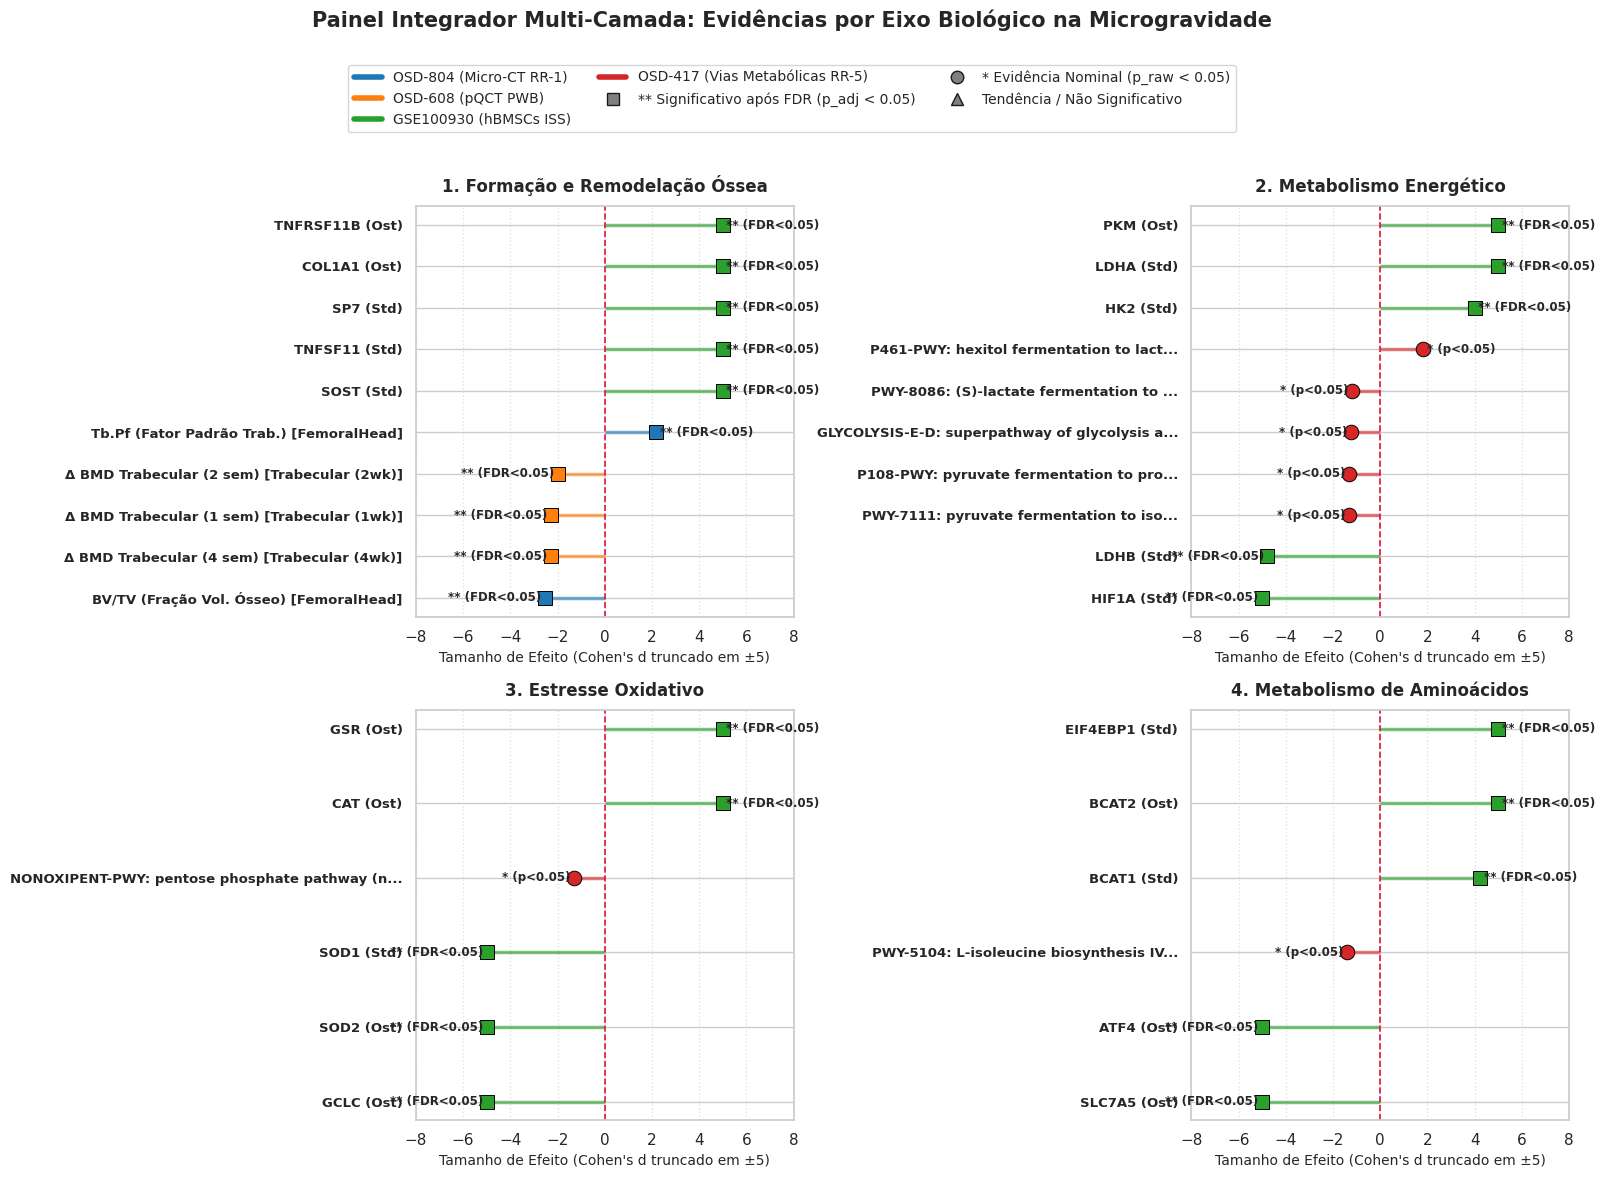

In [18]:

# 1. Filtrar para remover duplicatas do GSE100930 (usar Meio Osteogênico e Standard separados apenas onde mais relevante, ou pegar o menor p_raw por Variavel + Dataset)
df_limpo = (
    df_sintese[df_sintese["Regiao_Contexto"] != "Global (Flight vs Ground)"]
    .sort_values("p_raw")
    .drop_duplicates(subset=["Dataset", "Eixo_Biologico", "Variavel"], keep="first")
    .copy()
)

# 2. Encurtar nomes muito longos para o gráfico ficar elegante
def formatar_nome_variavel(row):
    var = str(row["Variavel"])
    # Traduzir/encurtar variáveis estruturais
    mapa_nomes = {
        "trabecular_thickness_millimeter": "Tb.Th (Espessura Trabecular)",
        "trabecular_separation_millimeter": "Tb.Sp (Separação Trabecular)",
        "trabecular_number_per_millimeter": "Tb.N (Número Trabecular)",
        "bone_volume_total_volume_millimeter_cubed": "BV/TV (Fração Vol. Ósseo)",
        "cortical_thickness_millimeter": "Ct.Th (Espessura Cortical)",
        "bone_area_total_area_millimeter_squared": "BA/TA (Área Óssea Cortical)",
        "connectivity_density_per_millimeter_cubed": "Conn.D (Densidade Conexão)",
        "trabecular_bone_pattern_factor": "Tb.Pf (Fator Padrão Trab.)",
        "trab_BMD_change_1wk": "Δ BMD Trabecular (1 sem)",
        "trab_BMD_change_2wk": "Δ BMD Trabecular (2 sem)",
        "trab_BMD_change_4wk": "Δ BMD Trabecular (4 sem)"
    }
    if var in mapa_nomes:
        var = f"{mapa_nomes[var]} [{row['Regiao_Contexto']}]"
    elif ":" in var:
        # Pegar o código PWY e o nome curto da via metabólica do OSD-417
        partes = var.split(":")
        var = f"{partes[0].strip()}: {partes[1].strip()[:28]}..."
    elif "GSE100930" in row["Dataset"]:
        meio_curto = "Ost" if "Osteogênico" in row["Regiao_Contexto"] else "Std"
        var = f"{var} ({meio_curto})"
    return var

df_limpo["Label_Grafico"] = df_limpo.apply(formatar_nome_variavel, axis=1)

# 3. Limitar (Winsorize) Cohen's d extremos em [-5, +5] apenas para visualização proporcional entre estudos
df_limpo["d_plot"] = df_limpo["Effect_Size_d"].clip(lower=-5.0, upper=5.0)

# 4. Criar figura com 4 Subplots (1 para cada Eixo Biológico)
eixos_ordem = [
    "1. Formação e Remodelação Óssea",
    "2. Metabolismo Energético",
    "3. Estresse Oxidativo",
    "4. Metabolismo de Aminoácidos"
]

cores_dataset = {
    "OSD-804 (Micro-CT RR-1)": "#1f77b4",          # Azul
    "OSD-608 (pQCT PWB)": "#ff7f0e",               # Laranja
    "GSE100930 (hBMSCs ISS)": "#2ca02c",           # Verde
    "OSD-417 (Vias Metabólicas RR-5)": "#d62728",  # Vermelho
    "OSD-417 (Microbioma RR-5)": "#9467bd"         # Roxo
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=False)
axes = axes.flatten()

for idx, eixo_nome in enumerate(eixos_ordem):
    ax = axes[idx]

    # Pegar até as Top 10 variáveis mais relevantes (menor p_raw) de cada eixo, garantindo diversidade de datasets
    sub_eixo = df_limpo[df_limpo["Eixo_Biologico"] == eixo_nome].copy()

    # Priorizar variáveis com p_raw < 0.10 (ou top 8 do eixo) para não poluir
    sub_sig = sub_eixo[sub_eixo["p_raw"] < 0.10]
    if len(sub_sig) < 5:
        sub_plot = sub_eixo.nsmallest(8, "p_raw").sort_values("d_plot")
    else:
        # Garantir que todos os datasets presentes no eixo apareçam no top
        sub_plot = (
            sub_sig.groupby("Dataset", group_keys=False)
            .apply(lambda x: x.nsmallest(5, "p_raw"))
            .nsmallest(10, "p_raw")
            .sort_values("d_plot")
        )

    # Plotar linhas horizontais (Lollipop / Forest Plot)
    y_pos = np.arange(len(sub_plot))
    cores = [cores_dataset.get(d, "#333333") for d in sub_plot["Dataset"]]

    ax.hlines(y=y_pos, xmin=0, xmax=sub_plot["d_plot"], color=cores, alpha=0.6, linewidth=2.5)

    # Plotar pontos diferenciando p_adj < 0.05 (estrela/quadrado cheio) vs p_raw < 0.05 (círculo)
    for i, (_, r) in enumerate(sub_plot.iterrows()):
        marcador = "s" if r["p_adj_fdr"] < 0.05 else ("o" if r["p_raw"] < 0.05 else "^")
        ax.scatter(
            r["d_plot"], i,
            color=cores_dataset.get(r["Dataset"], "#333333"),
            marker=marcador, s=110, zorder=3, edgecolors="black", linewidth=0.7
        )
        # Adicionar texto do p-valor ao lado da barra
        estrela = "** (FDR<0.05)" if r["p_adj_fdr"] < 0.05 else ("* (p<0.05)" if r["p_raw"] < 0.05 else f"(p={r['p_raw']:.2f})")
        offset = 0.15 if r["d_plot"] >= 0 else -0.15
        alinhamento = "left" if r["d_plot"] >= 0 else "right"
        ax.text(
            r["d_plot"] + offset, i, estrela,
            va="center", ha=alinhamento, fontsize=8.5, weight="bold" if r["p_raw"] < 0.05 else "normal"
        )

    ax.axvline(0, color="crimson", linestyle="--", linewidth=1.2)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sub_plot["Label_Grafico"], fontsize=9.5, weight="bold")
    ax.set_xlim(-8.0, 8.0)
    ax.set_title(eixo_nome, fontsize=12, weight="bold", pad=10)
    ax.set_xlabel("Tamanho de Efeito (Cohen's d truncado em ±5)", fontsize=10)
    ax.grid(axis="x", linestyle=":", alpha=0.6)

# Criar legenda única no topo da figura
from matplotlib.lines import Line2D
elementos_legenda = [
    Line2D([0], [0], color=cor, lw=4, label=ds)
    for ds, cor in cores_dataset.items() if ds in df_limpo["Dataset"].unique()
] + [
    Line2D([0], [0], marker="s", color="w", markerfacecolor="gray", markeredgecolor="k", markersize=9, label="** Significativo após FDR (p_adj < 0.05)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", markeredgecolor="k", markersize=9, label="* Evidência Nominal (p_raw < 0.05)"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="gray", markeredgecolor="k", markersize=9, label="Tendência / Não Significativo")
]

fig.suptitle("Painel Integrador Multi-Camada: Evidências por Eixo Biológico na Microgravidade", fontsize=15, weight="bold", y=0.98)
fig.legend(handles=elementos_legenda, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=3, frameon=True, fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.89])
plt.show()

/tmp/ipykernel_1754/1424038769.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1754/1424038769.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


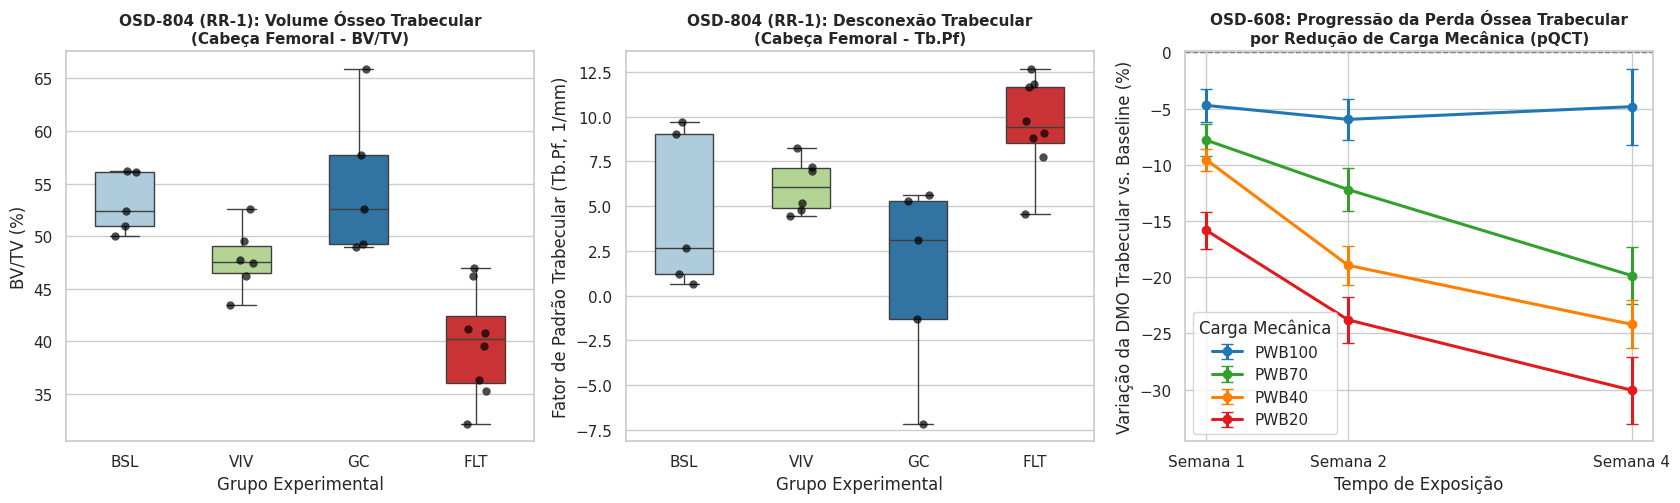

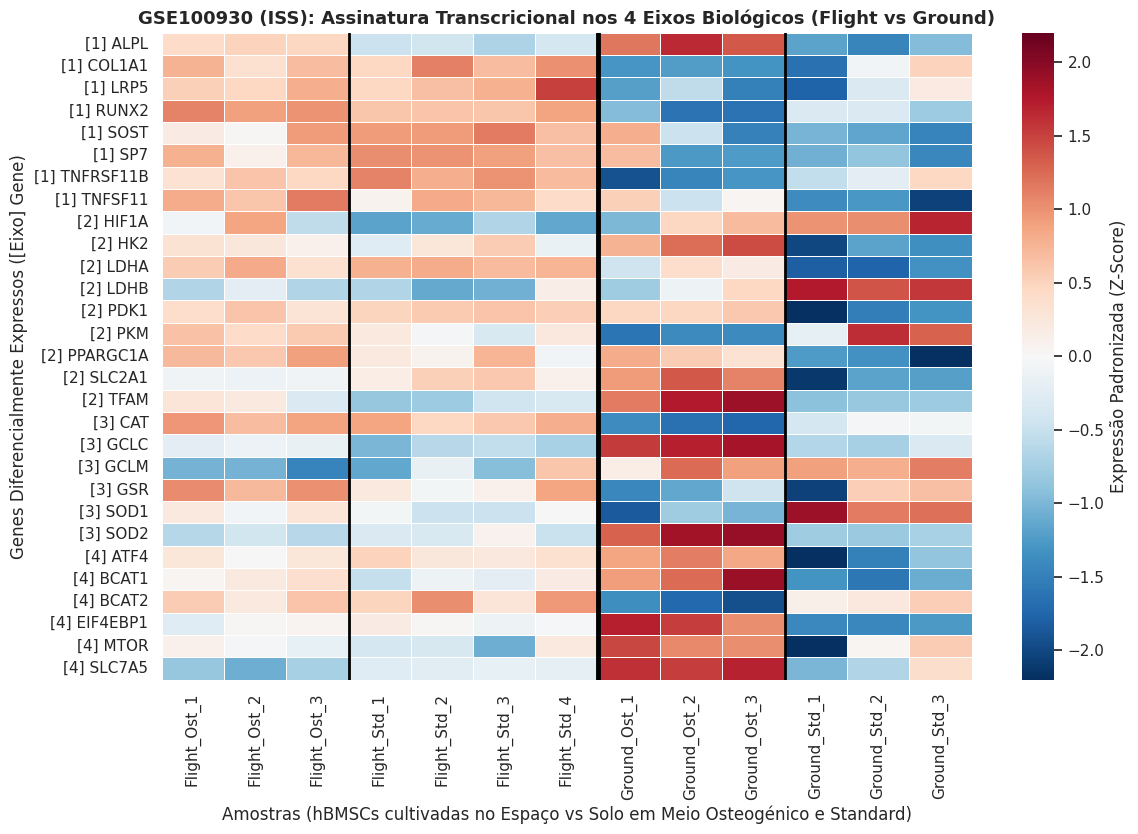

In [20]:
# ==============================================================================
# GRÁFICO COMPLEMENTAR 1: Evidências Estruturais Diretas (OSD-804 e OSD-608)
# ==============================================================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5.2))

# Subplot 1: OSD-804 BV/TV na Cabeça Femoral
sub_fh = df_804[df_804["regiao_ossea"] == "FemoralHead"]
ordem_804 = ["BSL", "VIV", "GC", "FLT"]
sns.boxplot(
    data=sub_fh, x="grupo_codigo", y="bone_volume_total_volume_millimeter_cubed",
    order=ordem_804, palette=["#a6cee3", "#b2df8a", "#1f78b4", "#e31a1c"], ax=ax1, width=0.5
)
sns.stripplot(
    data=sub_fh, x="grupo_codigo", y="bone_volume_total_volume_millimeter_cubed",
    order=ordem_804, color="black", alpha=0.7, size=6, ax=ax1
)
ax1.set_title("OSD-804 (RR-1): Volume Ósseo Trabecular\n(Cabeça Femoral - BV/TV)", fontsize=11, weight="bold")
ax1.set_xlabel("Grupo Experimental")
ax1.set_ylabel("BV/TV (%)")

# Subplot 2: OSD-804 Tb.Pf na Cabeça Femoral (Desconexão Trabecular)
sns.boxplot(
    data=sub_fh, x="grupo_codigo", y="trabecular_bone_pattern_factor",
    order=ordem_804, palette=["#a6cee3", "#b2df8a", "#1f78b4", "#e31a1c"], ax=ax2, width=0.5
)
sns.stripplot(
    data=sub_fh, x="grupo_codigo", y="trabecular_bone_pattern_factor",
    order=ordem_804, color="black", alpha=0.7, size=6, ax=ax2
)
ax2.set_title("OSD-804 (RR-1): Desconexão Trabecular\n(Cabeça Femoral - Tb.Pf)", fontsize=11, weight="bold")
ax2.set_xlabel("Grupo Experimental")
ax2.set_ylabel("Fator de Padrão Trabecular (Tb.Pf, 1/mm)")

# Subplot 3: OSD-608 Evolução Temporal da Perda Óssea por Nível de Carga
semanas = [1, 2, 4]
cols_mud = ["trab_change_1", "trab_change_2", "trab_change_4"]
cores_pwb = {"PWB100": "#1f78b4", "PWB70": "#33a02c", "PWB40": "#ff7f00", "PWB20": "#e31a1c"}

for grp in ["PWB100", "PWB70", "PWB40", "PWB20"]:
    medias = [df_608[df_608["PWB"] == grp][c].mean() for c in cols_mud]
    erros  = [df_608[df_608["PWB"] == grp][c].sem() for c in cols_mud]
    ax3.errorbar(semanas, medias, yerr=erros, marker="o", linewidth=2.2, capsize=4, label=grp, color=cores_pwb[grp])

ax3.axhline(0, color="gray", linestyle="--", linewidth=1)
ax3.set_xticks(semanas)
ax3.set_xticklabels(["Semana 1", "Semana 2", "Semana 4"])
ax3.set_title("OSD-608: Progressão da Perda Óssea Trabecular\npor Redução de Carga Mecânica (pQCT)", fontsize=11, weight="bold")
ax3.set_xlabel("Tempo de Exposição")
ax3.set_ylabel("Variação da DMO Trabecular vs. Baseline (%)")
ax3.legend(title="Carga Mecânica")

plt.tight_layout()
plt.savefig("evidencias_estruturais_osd804_osd608.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# GRÁFICO COMPLEMENTAR 2: Heatmap Molecular dos 4 Eixos no GSE100930 (Z-score)
# ==============================================================================
# Selecionar os genes significativos (FDR < 0.05 em pelo menos 1 comparação)
genes_sig_lista = df_res_930[df_res_930["p_adj_fdr"] < 0.05]["Variavel"].unique()
matriz_heat = df_genes_agg.loc[df_genes_agg.index.isin(genes_sig_lista), colunas_amostras].copy()

# Padronizar por linha (Z-score por gene) para visualizar o padrão relativo entre grupos
matriz_z = matriz_heat.sub(matriz_heat.mean(axis=1), axis=0).div(matriz_heat.std(axis=1), axis=0)

# Ordenar os genes pelo Eixo Biológico
ordem_genes_eixo = sorted(matriz_z.index, key=lambda g: (mapa_gene_eixo.get(g, ""), g))
matriz_z = matriz_z.loc[ordem_genes_eixo]
labels_y = [f"[{mapa_gene_eixo[g].split('.')[0]}] {g}" for g in matriz_z.index]

# Renomear colunas para indicar claramente Grupo e Meio
nomes_colunas = (
    [f"Flight_Ost_{i+1}" for i in range(len(flight_ost))] +
    [f"Flight_Std_{i+1}" for i in range(len(flight_std))] +
    [f"Ground_Ost_{i+1}" for i in range(len(ground_ost))] +
    [f"Ground_Std_{i+1}" for i in range(len(ground_std))]
)
matriz_z.columns = nomes_colunas

plt.figure(figsize=(12, 8.5))
sns.heatmap(
    matriz_z, cmap="RdBu_r", center=0, vmin=-2.2, vmax=2.2,
    yticklabels=labels_y, cbar_kws={"label": "Expressão Padronizada (Z-Score)"},
    linewidths=0.5, linecolor="white"
)
plt.axvline(3, color="black", linewidth=2)
plt.axvline(7, color="black", linewidth=3.5)
plt.axvline(10, color="black", linewidth=2)
plt.title("GSE100930 (ISS): Assinatura Transcricional nos 4 Eixos Biológicos (Flight vs Ground)", fontsize=13, weight="bold")
plt.xlabel("Amostras (hBMSCs cultivadas no Espaço vs Solo em Meio Osteogénico e Standard)")
plt.ylabel("Genes Diferencialmente Expressos ([Eixo] Gene)")
plt.tight_layout()
plt.savefig("heatmap_molecular_gse100930_4eixos.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# Dados individuais do GSE100930 no formato longo para os gráficos dos 4 Eixos
amostras_info = (
    [(s, "Flight", "Osteogenic", "Flight (Ost)") for s in flight_ost] +
    [(s, "Flight", "Standard", "Flight (Std)") for s in flight_std] +
    [(s, "Ground", "Osteogenic", "Ground (Ost)") for s in ground_ost] +
    [(s, "Ground", "Standard", "Ground (Std)") for s in ground_std]
)
df_meta_930 = pd.DataFrame(amostras_info, columns=["Amostra", "Condicao", "Meio", "Grupo_Label"])

df_long_930 = (
    df_genes_agg.reset_index()
    .melt(id_vars="gene", var_name="Amostra", value_name="Expressao_Log2")
    .merge(df_meta_930, on="Amostra")
)

/tmp/ipykernel_1754/2690731298.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


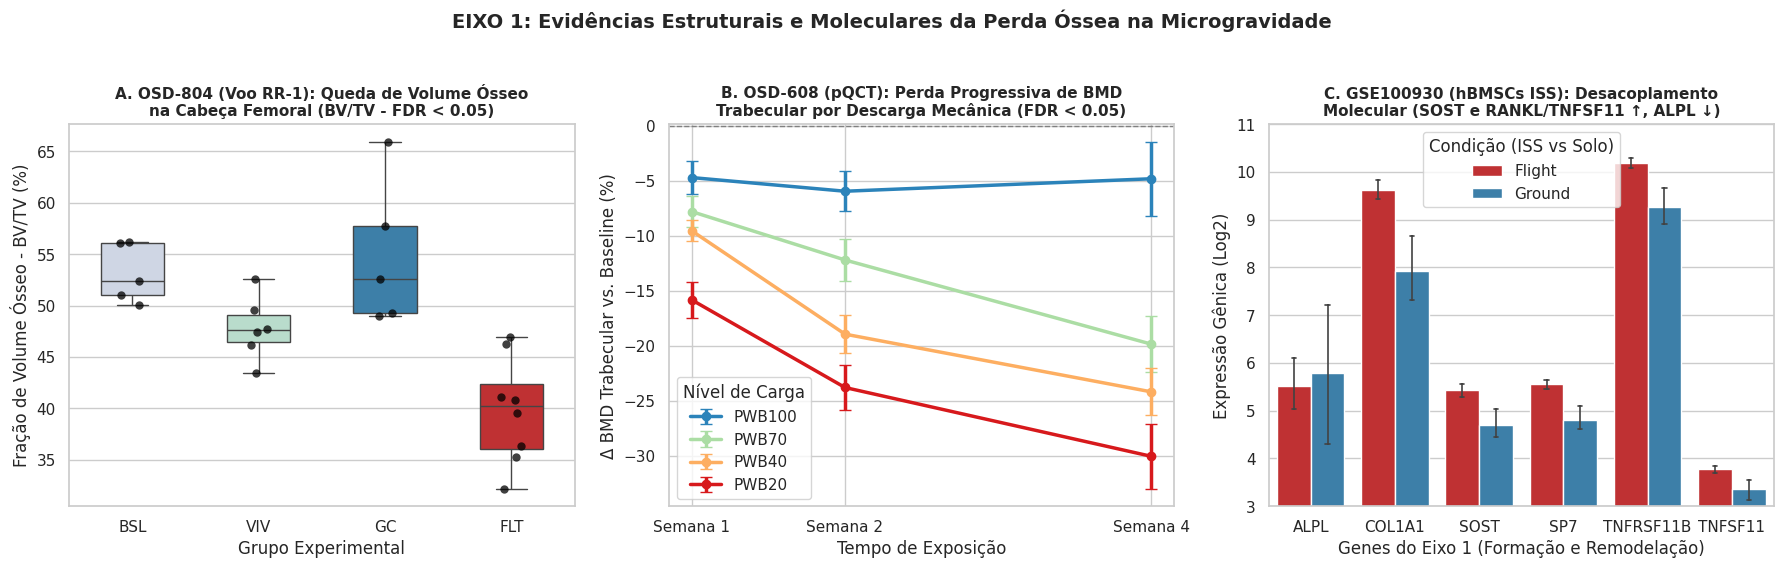

In [24]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# 1A. OSD-804: BV/TV e Tb.Pf na Cabeça Femoral
sub_fh = df_804[df_804["regiao_ossea"] == "FemoralHead"].copy()
ordem_804 = ["BSL", "VIV", "GC", "FLT"]
sns.boxplot(
    data=sub_fh, x="grupo_codigo", y="bone_volume_total_volume_millimeter_cubed",
    order=ordem_804, palette=["#cbd5e8", "#b3e2cd", "#2b83ba", "#d7191c"], ax=ax1, width=0.5
)
sns.stripplot(
    data=sub_fh, x="grupo_codigo", y="bone_volume_total_volume_millimeter_cubed",
    order=ordem_804, color="black", alpha=0.75, size=6, ax=ax1
)
ax1.set_title("A. OSD-804 (Voo RR-1): Queda de Volume Ósseo\nna Cabeça Femoral (BV/TV - FDR < 0.05)", fontsize=11, weight="bold")
ax1.set_xlabel("Grupo Experimental")
ax1.set_ylabel("Fração de Volume Ósseo - BV/TV (%)")

# 1B. OSD-608: Evolução Temporal da Perda de DMO Trabecular
semanas = [1, 2, 4]
cols_mud = ["trab_change_1", "trab_change_2", "trab_change_4"]
cores_pwb = {"PWB100": "#2b83ba", "PWB70": "#abdda4", "PWB40": "#fdae61", "PWB20": "#d7191c"}

for grp in ["PWB100", "PWB70", "PWB40", "PWB20"]:
    medias = [df_608[df_608["PWB"] == grp][c].mean() for c in cols_mud]
    erros  = [df_608[df_608["PWB"] == grp][c].sem() for c in cols_mud]
    ax2.errorbar(semanas, medias, yerr=erros, marker="o", linewidth=2.5, capsize=4, label=grp, color=cores_pwb[grp])

ax2.axhline(0, color="gray", linestyle="--", linewidth=1)
ax2.set_xticks(semanas)
ax2.set_xticklabels(["Semana 1", "Semana 2", "Semana 4"])
ax2.set_title("B. OSD-608 (pQCT): Perda Progressiva de BMD\nTrabecular por Descarga Mecânica (FDR < 0.05)", fontsize=11, weight="bold")
ax2.set_xlabel("Tempo de Exposição")
ax2.set_ylabel("Δ BMD Trabecular vs. Baseline (%)")
ax2.legend(title="Nível de Carga")

# 1C. GSE100930: Expressão de Genes de Remodelação Óssea
genes_eixo1 = ["ALPL", "SOST", "TNFSF11", "COL1A1", "SP7", "TNFRSF11B"]
sub_g1 = df_long_930[df_long_930["gene"].isin(genes_eixo1)]
sns.barplot(
    data=sub_g1, x="gene", y="Expressao_Log2", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, capsize=0.1, err_kws={'linewidth': 1.2}, ax=ax3
)
ax3.set_title("C. GSE100930 (hBMSCs ISS): Desacoplamento\nMolecular (SOST e RANKL/TNFSF11 ↑, ALPL ↓)", fontsize=11, weight="bold")
ax3.set_xlabel("Genes do Eixo 1 (Formação e Remodelação)")
ax3.set_ylabel("Expressão Gênica (Log2)")
ax3.set_ylim(3, 11)
ax3.legend(title="Condição (ISS vs Solo)")

plt.suptitle("EIXO 1: Evidências Estruturais e Moleculares da Perda Óssea na Microgravidade", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()
plt.savefig("eixo1_remodelacao_ossea.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1754/2167096173.py:28: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1754/2167096173.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


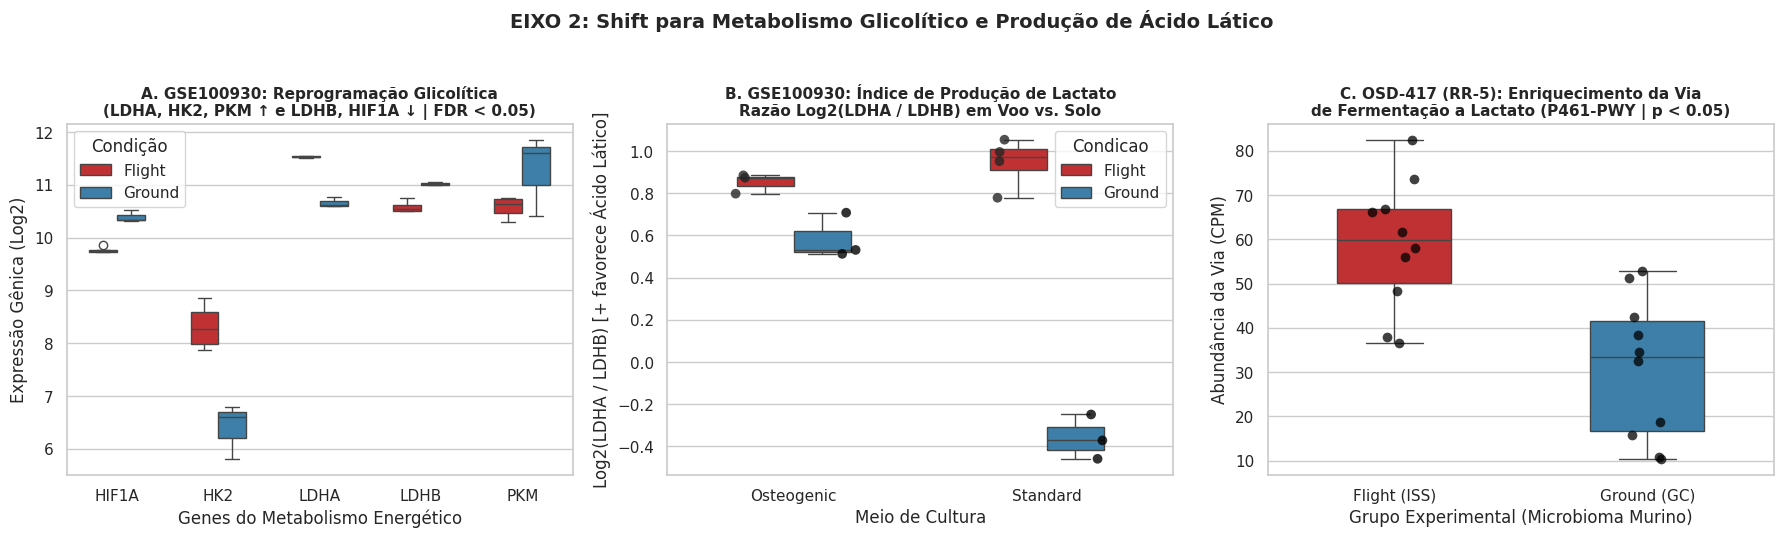

In [25]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.2))

# 2A. GSE100930: Enzimas Glicolíticas (Meio Standard, onde o shift é mais pronunciado)
genes_eixo2 = ["LDHA", "LDHB", "HK2", "PKM", "HIF1A"]
sub_g2 = df_long_930[(df_long_930["gene"].isin(genes_eixo2)) & (df_long_930["Meio"] == "Standard")]

sns.boxplot(
    data=sub_g2, x="gene", y="Expressao_Log2", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, ax=ax1, width=0.55
)
ax1.set_title("A. GSE100930: Reprogramação Glicolítica\n(LDHA, HK2, PKM ↑ e LDHB, HIF1A ↓ | FDR < 0.05)", fontsize=11, weight="bold")
ax1.set_xlabel("Genes do Metabolismo Energético")
ax1.set_ylabel("Expressão Gênica (Log2)")
ax1.legend(title="Condição")

# 2B. GSE100930: Razão Produtor/Consumidor de Ácido Lático (LDHA - LDHB em Log2)
ldha_vals = df_genes_agg.loc["LDHA", colunas_amostras]
ldhb_vals = df_genes_agg.loc["LDHB", colunas_amostras]
df_razao = pd.DataFrame({
    "Amostra": colunas_amostras,
    "Razao_Log2_LDHA_LDHB": (ldha_vals - ldhb_vals).values
}).merge(df_meta_930, on="Amostra")

sns.boxplot(
    data=df_razao, x="Meio", y="Razao_Log2_LDHA_LDHB", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, ax=ax2, width=0.45
)
sns.stripplot(
    data=df_razao, x="Meio", y="Razao_Log2_LDHA_LDHB", hue="Condicao",
    dodge=True, color="black", alpha=0.8, size=7, legend=False, ax=ax2
)
ax2.set_title("B. GSE100930: Índice de Produção de Lactato\nRazão Log2(LDHA / LDHB) em Voo vs. Solo", fontsize=11, weight="bold")
ax2.set_xlabel("Meio de Cultura")
ax2.set_ylabel("Log2(LDHA / LDHB) [+ favorece Ácido Lático]")

# 2C. OSD-417: Via Microbiana de Fermentação a Lactato (P461-PWY)
if caminho_pw and caminho_pw.exists():
    linha_p461 = df_pw[df_pw[col_id].str.contains("P461-PWY", na=False) & (~df_pw[col_id].str.contains(r"\|"))]
    if not linha_p461.empty:
        vf_p461 = linha_p461[cols_f_417].values.flatten().astype(float)
        vg_p461 = linha_p461[cols_gc_417].values.flatten().astype(float)
        df_plot_417_lac = pd.DataFrame({
            "Grupo": ["Flight (ISS)"] * len(vf_p461) + ["Ground (GC)"] * len(vg_p461),
            "Abundancia_CPM": np.concatenate([vf_p461, vg_p461])
        })
        sns.boxplot(
            data=df_plot_417_lac, x="Grupo", y="Abundancia_CPM",
            palette={"Flight (ISS)": "#d7191c", "Ground (GC)": "#2b83ba"}, width=0.45, ax=ax3
        )
        sns.stripplot(
            data=df_plot_417_lac, x="Grupo", y="Abundancia_CPM",
            color="black", alpha=0.75, size=7, ax=ax3
        )
        ax3.set_title("C. OSD-417 (RR-5): Enriquecimento da Via\nde Fermentação a Lactato (P461-PWY | p < 0.05)", fontsize=11, weight="bold")
        ax3.set_xlabel("Grupo Experimental (Microbioma Murino)")
        ax3.set_ylabel("Abundância da Via (CPM)")

plt.suptitle("EIXO 2: Shift para Metabolismo Glicolítico e Produção de Ácido Lático", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()
plt.savefig("eixo2_metabolismo_energetico_lactato.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1754/2187532856.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


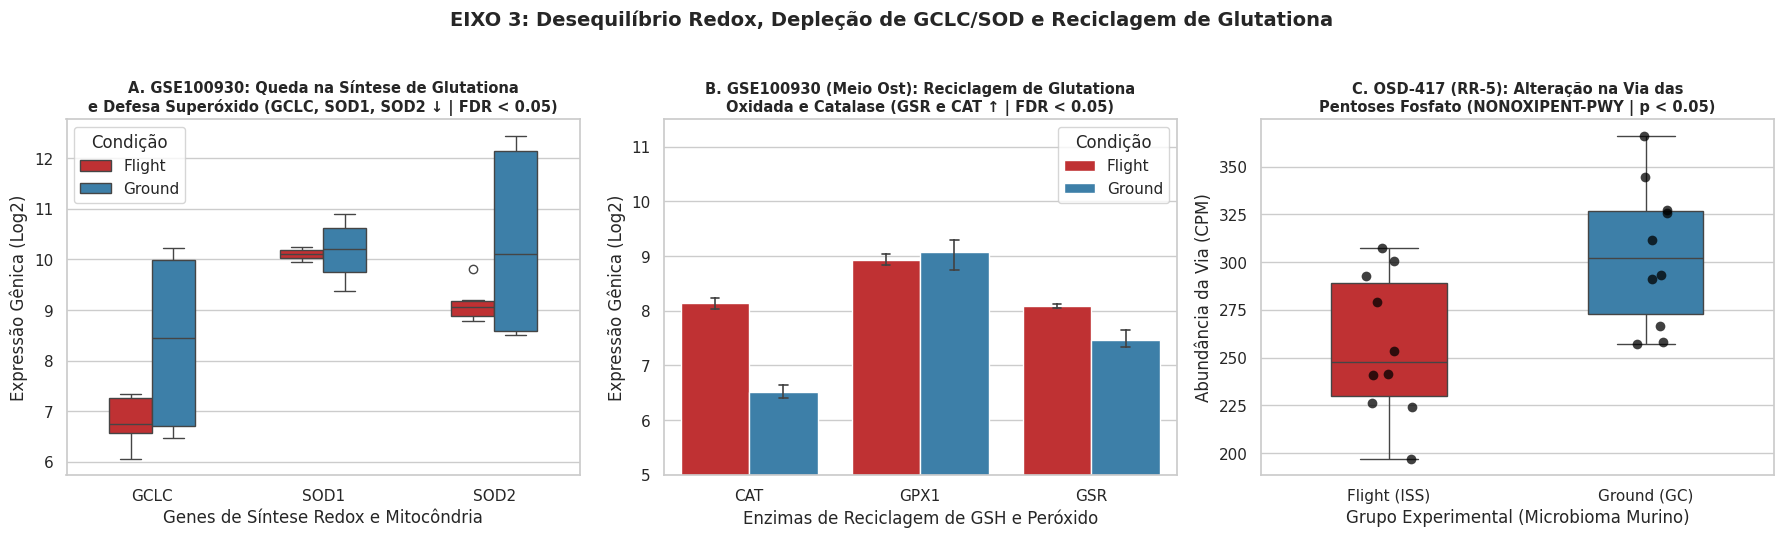

In [26]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.2))

# 3A. GSE100930: Queda na Síntese de Glutationa (GCLC) e Defesa Superóxido (SOD1, SOD2)
genes_queda_ox = ["GCLC", "SOD1", "SOD2"]
sub_ox1 = df_long_930[df_long_930["gene"].isin(genes_queda_ox)]
sns.boxplot(
    data=sub_ox1, x="gene", y="Expressao_Log2", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, ax=ax1, width=0.5
)
ax1.set_title("A. GSE100930: Queda na Síntese de Glutationa\ne Defesa Superóxido (GCLC, SOD1, SOD2 ↓ | FDR < 0.05)", fontsize=10.5, weight="bold")
ax1.set_xlabel("Genes de Síntese Redox e Mitocôndria")
ax1.set_ylabel("Expressão Gênica (Log2)")
ax1.legend(title="Condição")

# 3B. GSE100930: Resposta Compensatória de Reciclagem (GSR e CAT em Meio Osteogênico)
genes_comp_ox = ["GSR", "CAT", "GPX1"]
sub_ox2 = df_long_930[(df_long_930["gene"].isin(genes_comp_ox)) & (df_long_930["Meio"] == "Osteogenic")]
sns.barplot(
    data=sub_ox2, x="gene", y="Expressao_Log2", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, capsize=0.1, err_kws={'linewidth': 1.2}, ax=ax2
)
ax2.set_title("B. GSE100930 (Meio Ost): Reciclagem de Glutationa\nOxidada e Catalase (GSR e CAT ↑ | FDR < 0.05)", fontsize=10.5, weight="bold")
ax2.set_xlabel("Enzimas de Reciclagem de GSH e Peróxido")
ax2.set_ylabel("Expressão Gênica (Log2)")
ax2.set_ylim(5, 11.5)
ax2.legend(title="Condição")

# 3C. OSD-417: Via das Pentoses Fosfato (NONOXIPENT-PWY)
if caminho_pw and caminho_pw.exists():
    linha_pent = df_pw[df_pw[col_id].str.contains("NONOXIPENT-PWY", na=False) & (~df_pw[col_id].str.contains(r"\|"))]
    if not linha_pent.empty:
        vf_p = linha_pent[cols_f_417].values.flatten().astype(float)
        vg_p = linha_pent[cols_gc_417].values.flatten().astype(float)
        df_plot_417_ox = pd.DataFrame({
            "Grupo": ["Flight (ISS)"] * len(vf_p) + ["Ground (GC)"] * len(vg_p),
            "Abundancia_CPM": np.concatenate([vf_p, vg_p])
        })
        sns.boxplot(
            data=df_plot_417_ox, x="Grupo", y="Abundancia_CPM",
            palette={"Flight (ISS)": "#d7191c", "Ground (GC)": "#2b83ba"}, width=0.45, ax=ax3
        )
        sns.stripplot(
            data=df_plot_417_ox, x="Grupo", y="Abundancia_CPM",
            color="black", alpha=0.75, size=7, ax=ax3
        )
        ax3.set_title("C. OSD-417 (RR-5): Alteração na Via das\nPentoses Fosfato (NONOXIPENT-PWY | p < 0.05)", fontsize=10.5, weight="bold")
        ax3.set_xlabel("Grupo Experimental (Microbioma Murino)")
        ax3.set_ylabel("Abundância da Via (CPM)")

plt.suptitle("EIXO 3: Desequilíbrio Redox, Depleção de GCLC/SOD e Reciclagem de Glutationa", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()
plt.savefig("eixo3_estresse_oxidativo_glutationa.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1754/4139689622.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


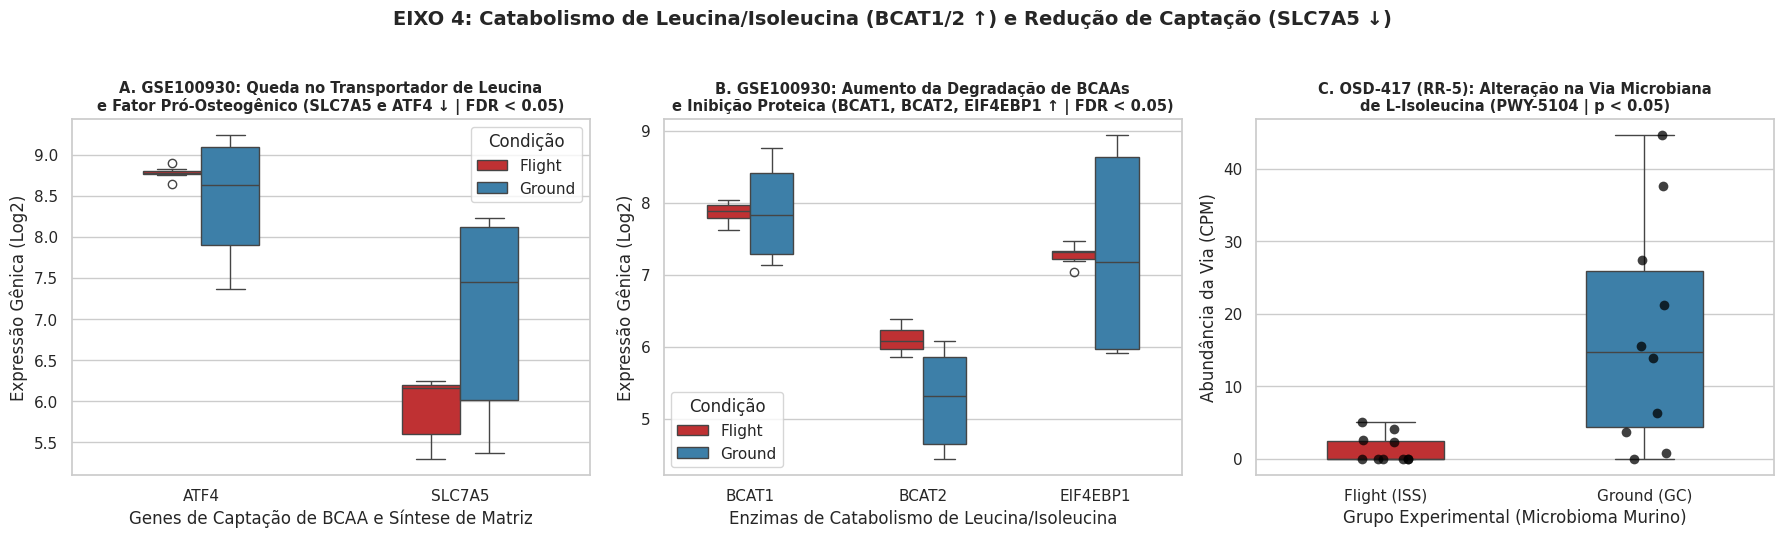

In [27]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.2))

# 4A. GSE100930: Bloqueio de Captação de Leucina (SLC7A5) e Anabolismo (ATF4)
sub_aa1 = df_long_930[df_long_930["gene"].isin(["SLC7A5", "ATF4"])]
sns.boxplot(
    data=sub_aa1, x="gene", y="Expressao_Log2", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, ax=ax1, width=0.45
)
ax1.set_title("A. GSE100930: Queda no Transportador de Leucina\ne Fator Pró-Osteogênico (SLC7A5 e ATF4 ↓ | FDR < 0.05)", fontsize=10.5, weight="bold")
ax1.set_xlabel("Genes de Captação de BCAA e Síntese de Matriz")
ax1.set_ylabel("Expressão Gênica (Log2)")
ax1.legend(title="Condição")

# 4B. GSE100930: Aumento do Catabolismo de Leucina/Isoleucina (BCAT1, BCAT2) e Repressão de Tradução (EIF4EBP1)
sub_aa2 = df_long_930[df_long_930["gene"].isin(["BCAT1", "BCAT2", "EIF4EBP1"])]
sns.boxplot(
    data=sub_aa2, x="gene", y="Expressao_Log2", hue="Condicao",
    palette={"Flight": "#d7191c", "Ground": "#2b83ba"}, ax=ax2, width=0.5
)
ax2.set_title("B. GSE100930: Aumento da Degradação de BCAAs\ne Inibição Proteica (BCAT1, BCAT2, EIF4EBP1 ↑ | FDR < 0.05)", fontsize=10.5, weight="bold")
ax2.set_xlabel("Enzimas de Catabolismo de Leucina/Isoleucina")
ax2.set_ylabel("Expressão Gênica (Log2)")
ax2.legend(title="Condição")

# 4C. OSD-417: Via de Biossíntese de L-Isoleucina (PWY-5104)
if caminho_pw and caminho_pw.exists():
    linha_iso = df_pw[df_pw[col_id].str.contains("PWY-5104", na=False) & (~df_pw[col_id].str.contains(r"\|"))]
    if not linha_iso.empty:
        vf_i = linha_iso[cols_f_417].values.flatten().astype(float)
        vg_i = linha_iso[cols_gc_417].values.flatten().astype(float)
        df_plot_417_aa = pd.DataFrame({
            "Grupo": ["Flight (ISS)"] * len(vf_i) + ["Ground (GC)"] * len(vg_i),
            "Abundancia_CPM": np.concatenate([vf_i, vg_i])
        })
        sns.boxplot(
            data=df_plot_417_aa, x="Grupo", y="Abundancia_CPM",
            palette={"Flight (ISS)": "#d7191c", "Ground (GC)": "#2b83ba"}, width=0.45, ax=ax3
        )
        sns.stripplot(
            data=df_plot_417_aa, x="Grupo", y="Abundancia_CPM",
            color="black", alpha=0.75, size=7, ax=ax3
        )
        ax3.set_title("C. OSD-417 (RR-5): Alteração na Via Microbiana\nde L-Isoleucina (PWY-5104 | p < 0.05)", fontsize=10.5, weight="bold")
        ax3.set_xlabel("Grupo Experimental (Microbioma Murino)")
        ax3.set_ylabel("Abundância da Via (CPM)")

plt.suptitle("EIXO 4: Catabolismo de Leucina/Isoleucina (BCAT1/2 ↑) e Redução de Captação (SLC7A5 ↓)", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()
plt.savefig("eixo4_aminoacidos_leucina_isoleucina.png", dpi=300, bbox_inches="tight")
plt.show()